# Table of Contents
- 1. Complex Aggregations with Named Aggregations
- 2. Pivot Tables and Crosstabs with Margins
- 3. Reshaping with Melt, Stack, and Unstack
- 4. Window Operations in Pandas (`rolling`, `expanding`, `ewm`) ewm => Exponential Weigted Moving

In [1]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for grouping, pivoting, and reshaping loaded successfully.")

Global libraries for grouping, pivoting, and reshaping loaded successfully.


- 1. Complex Aggregations with Named Aggregations

            mean_salary  max_tenure
department                         
HR              52000.0           6
IT              88500.0           5
Sales           67500.0           7


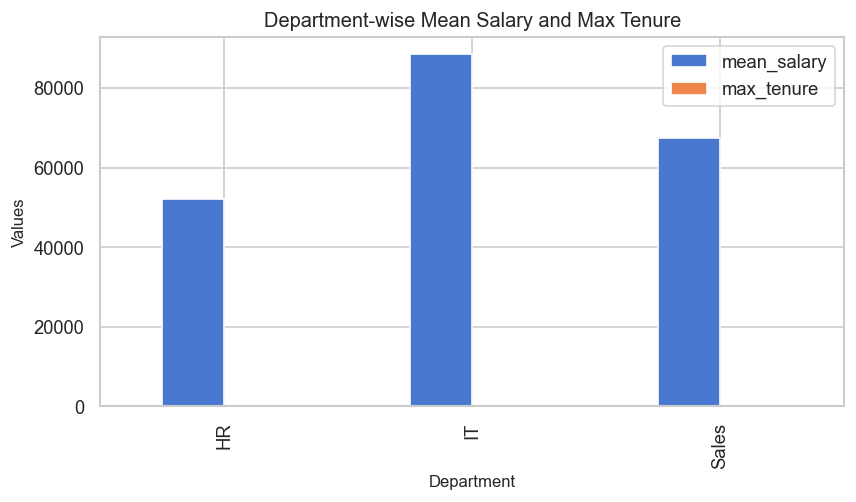

In [2]:
df_agg = pd.DataFrame({
    'department': ['IT', 'IT', 'HR', 'HR', 'Sales', 'Sales'],
    'salary': [85000, 92000, 50000, 54000, 65000, 70000],
    'tenure': [3, 5, 2, 6, 4, 7]
})

# named Aggregated DataFrame
# summary_df = df_agg.groupby('department').agg({
#     'salary': ['mean','sum','count'],
#     'tenure': ['max']
# })

summary_df = df_agg.groupby('department').agg(
    mean_salary= ('salary', 'mean'),
    max_tenure= ('tenure', 'max')
)

print(summary_df)

# visualization
summary_df.plot(kind='bar')
plt.title('Department-wise Mean Salary and Max Tenure')
plt.ylabel('Values')
plt.xlabel('Department')
plt.show()

- 2. Pivot Tables and Crosstabs with Margins

In [3]:
df_pivot = pd.DataFrame({
    'device': ['Mobile', 'Desktop', 'Mobile', 'Desktop', 'Mobile', 'Desktop'],
    'region': ['North', 'North', 'South', 'South', 'North', 'South'],
    'sales': [200, 450, 300, 500, 250, 400]
})
print(df_pivot)
print("_" * 60)
pivot_res1=df_pivot.pivot_table(index='region', columns='device', values='sales',aggfunc ='sum')
print(pivot_res1)
print("_" * 60)
pivot_res2=df_pivot.pivot_table(index='region', columns='device', values='sales',aggfunc ='sum',margins=True)
print(pivot_res2)
print("_" * 60)
pivot_res3=df_pivot.pivot_table(index='device', columns='region', values='sales',aggfunc ='sum',margins=True)
print(pivot_res3)
print("_" * 60)

    device region  sales
0   Mobile  North    200
1  Desktop  North    450
2   Mobile  South    300
3  Desktop  South    500
4   Mobile  North    250
5  Desktop  South    400
____________________________________________________________
device  Desktop  Mobile
region                 
North       450     450
South       900     300
____________________________________________________________
device  Desktop  Mobile   All
region                       
North       450     450   900
South       900     300  1200
All        1350     750  2100
____________________________________________________________
region   North  South   All
device                     
Desktop    450    900  1350
Mobile     450    300   750
All        900   1200  2100
____________________________________________________________


- 3. Reshaping with Melt, Stack, and Unstack

In [4]:
df_wide = pd.DataFrame({
    'product': ['Widget A', 'Widget B'],
    'Jan': [100, 150],
    'Feb': [120, 170]
})
print(df_wide)
print("_" * 60)
# Melt wide to long
df_long = pd.melt(df_wide, id_vars=['product'], value_vars=['Jan', 'Feb'], var_name='Month', value_name='Sales')
print("Melted Long Format:\n", df_long)

    product  Jan  Feb
0  Widget A  100  120
1  Widget B  150  170
____________________________________________________________
Melted Long Format:
     product Month  Sales
0  Widget A   Jan    100
1  Widget B   Jan    150
2  Widget A   Feb    120
3  Widget B   Feb    170


4. Window Operations in Pandas (`rolling`, `expanding`, `ewm`) ewm => Exponential Weigted Moving.
### 2. Math Formula
For a rolling window of size $k$, the rolling mean at time $t$ is:
$$\text{RollingMean}_t = \frac{1}{k} \sum_{i=0}^{k-1} x_{t-i}$$
For exponentially weighted moving average ($	ext{EWM}$) with smoothing factor $\alpha$:
$$\text{EWM}_t = \alpha x_t + (1 - \alpha)\text{EWM}_{t-1}$$

### 3. Notation Pronunciation
- `rolling(window=3)`: "Rolling window of size three"
- $\alpha$: "Alpha smoothing factor parameter"

### 4. Naive Example
Calculating a 3-day moving average stock price to smooth out short-term market fluctuations and reveal underlying trends.

        date  value
0 2026-01-01     88
1 2026-01-02     78
2 2026-01-03     64
3 2026-01-04     92
4 2026-01-05     57
____________________________________________________________
        date  value  rolling_mean
0 2026-01-01     88           NaN
1 2026-01-02     78           NaN
2 2026-01-03     64     76.666667
3 2026-01-04     92     78.000000
4 2026-01-05     57     71.000000


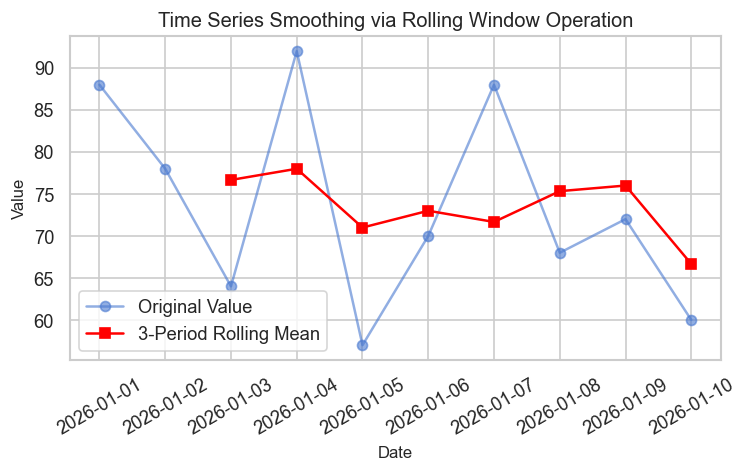

In [5]:
np.random.seed(42)
dates = pd.date_range(start='2026-01-01', periods=10)
df_ts = pd.DataFrame({
    'date': dates,
    'value': np.random.randint(50, 100, 10)
})
print(df_ts.head(5))
print("_" * 60)
df_ts['rolling_mean'] = df_ts['value'].rolling(window=3).mean()
print(df_ts.head(5))

# Visualization
plt.figure(figsize=(7, 3.5))
plt.plot(df_ts['date'], df_ts['value'], marker='o', label='Original Value', alpha=0.6)
plt.plot(df_ts['date'], df_ts['rolling_mean'], marker='s', label='3-Period Rolling Mean', color='red')
plt.title('Time Series Smoothing via Rolling Window Operation')
plt.xlabel('Date')
plt.ylabel('Value')
plt.legend()
plt.xticks(rotation=30)
plt.show()

## Summary Table

| Reshaping / Aggregation Technique | Primary Syntax / Function | Directionality / Structure | Primary Analytical Purpose |
| :--- | :--- | :--- | :--- |
| **Named Aggregations** | `groupby().agg(col=('src', 'func'))` | Many-to-one summary | Generating clean, explicitly labeled tabular reports |
| **Pivot Tables & Crosstabs** | `pivot_table()`, `crosstab(..., margins=True)` | Two-dimensional cross-classification | Multi-variable frequency counts and sums with totals |
| **Melt & Reshaping** | `pd.melt()`, `.stack()`, `.unstack()` | Wide to long / Hierarchical toggle | Formatting data structures for visualization pipelines |
| **Window Operations** | `.rolling()`, `.expanding()`, `.ewm()` | Sequential / Temporal sliding | Smoothing time-series trends and feature extraction |